In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_path = Path("data/train.csv")
test_path = Path("data/test.csv")

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())

Train shape: (891, 12)
Test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print("Train columns:", train.columns.tolist())
print("Test columns:", test.columns.tolist())

Train columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Test columns: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [3]:
missing_summary = pd.DataFrame({
    "Missing count": train.isna().sum(),
    "Missing (%)": train.isna().mean() * 100,
})

missing_summary = missing_summary.sort_values(
    "Missing (%)",
    ascending=False
)

display(missing_summary.round(2))

,Missing count,Missing (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
SibSp,0,0.00
Parch,0,0.00


In [4]:
test_missing_summary = pd.DataFrame({
    "Missing count": test.isna().sum(),
    "Missing (%)": test.isna().mean() * 100,
})

display(
    test_missing_summary.sort_values(
        "Missing (%)",
        ascending=False
    ).round(2)
)

,Missing count,Missing (%)
Cabin,327,78.23
Age,86,20.57
Fare,1,0.24
PassengerId,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00


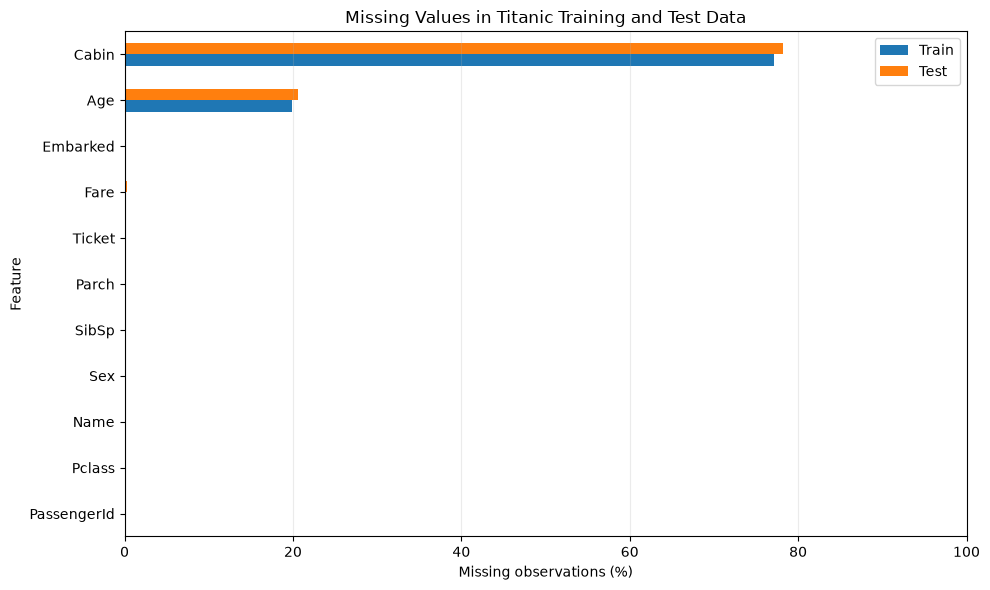

In [5]:
train_missing = train.isna().mean() * 100
test_missing = test.isna().mean() * 100

features = [
    col for col in train.columns
    if col != "Survived" and col in test.columns
]

missing_comparison = pd.DataFrame({
    "Train": train_missing.reindex(features),
    "Test": test_missing.reindex(features)
})

missing_comparison = missing_comparison.sort_values(
    "Train",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

missing_comparison.plot(
    kind="barh",
    ax=ax
)

ax.set_title(
    "Missing Values in Titanic Training and Test Data"
)
ax.set_xlabel("Missing observations (%)")
ax.set_ylabel("Feature")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [6]:
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

fig.savefig(
    figures_dir / "missingness_train_test_E.png",
    dpi=200,
    bbox_inches="tight"
)

In [7]:
candidate_features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "Cabin",
]

candidate_features = [
    col for col in candidate_features
    if col in train.columns
]

complete_all = train[candidate_features].dropna().shape[0]

without_cabin = [
    col for col in candidate_features
    if col != "Cabin"
]

complete_without_cabin = train[
    without_cabin
].dropna().shape[0]

summary = pd.DataFrame({
    "Strategy": [
        "All candidate features complete",
        "Excluding Cabin",
        "Original training dataset",
    ],
    "Observations retained": [
        complete_all,
        complete_without_cabin,
        len(train),
    ]
})

summary["Retained (%)"] = (
    summary["Observations retained"]
    / len(train)
    * 100
)

display(summary.round(2))

,Strategy,Observations retained,Retained (%)
0,All candidate features complete,183,20.54
1,Excluding Cabin,712,79.91
2,Original training dataset,891,100.00


In [8]:
cabin_analysis = train.copy()

cabin_analysis["Cabin recorded"] = (
    cabin_analysis["Cabin"].notna()
)

cabin_survival = (
    cabin_analysis
    .groupby("Cabin recorded")["Survived"]
    .agg(
        Survival_rate="mean",
        Count="size",
    )
    .reset_index()
)

cabin_survival["Survival (%)"] = (
    cabin_survival["Survival_rate"] * 100
)

display(cabin_survival.round(2))

,Cabin recorded,Survival_rate,Count,Survival (%)
0,False,0.30,687,29.99
1,True,0.67,204,66.67


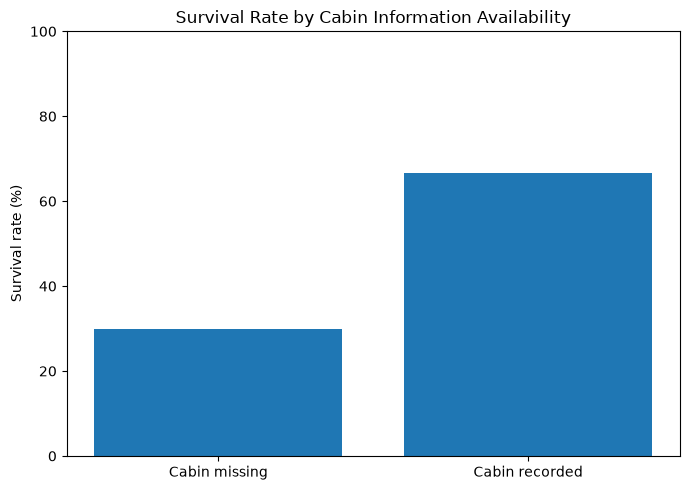

In [9]:
fig2, ax2 = plt.subplots(figsize=(7, 5))

labels = cabin_survival["Cabin recorded"].map({
    False: "Cabin missing",
    True: "Cabin recorded"
})

ax2.bar(
    labels,
    cabin_survival["Survival (%)"]
)

ax2.set_title(
    "Survival Rate by Cabin Information Availability"
)
ax2.set_ylabel("Survival rate (%)")
ax2.set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [10]:
fig2.savefig(
    figures_dir / "cabin_availability_survival_E.png",
    dpi=200,
    bbox_inches="tight"
)

### Conclusion: Missingness and Feature Availability

The Titanic training dataset contains 891 passengers, while the test dataset contains 418. **Cabin has the highest missingness**, with 77.10% of training values and 78.23% of test values missing. Age also has substantial missingness (19.87% and 20.57%, respectively).

Requiring complete data across all eight candidate features would retain only 183 training passengers (20.54%). Excluding Cabin from this requirement increases the number of complete observations to 712 (79.91%). This suggests that deleting all incomplete records would result in substantial information loss.

Interestingly, passengers with recorded Cabin information had a survival rate of 66.67%, compared with 29.99% among passengers whose Cabin information was missing. This 36.68-percentage-point difference suggests that Cabin information availability may contain useful predictive signals. However, the association may be confounded by passenger class or socioeconomic factors and should not be interpreted causally.

For survival prediction, relatively complete features such as Sex and Pclass are practical candidates. Age could be retained through appropriate imputation, while Cabin may be better represented through a missingness indicator or carefully derived features rather than its raw values. These choices should be evaluated using validation data.